# Problema 4 - Classificação de risco de crédito com Árvores de Decisão (UCI Statlog German Credit Data, arquivo german.data, 1.000 solicitações).

Convenção das classes (a classe POSITIVA é o mau pagador, que é o evento
que o banco quer detectar):
    0 = bom pagador (no arquivo original: 1)
    1 = mau pagador (no arquivo original: 2)


In [1]:
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# ----------------------------------------------------------------------------
# Configurações gerais
# ----------------------------------------------------------------------------
BASE = Path.cwd()  # abra o notebook DENTRO da pasta do problema (ao lado de dados/)
ARQ_DADOS = BASE / "dados" / "german.data"
PASTA_FIG = BASE / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

pd.set_option("display.width", 200)       # tabelas largas sem quebrar colunas
pd.set_option("display.max_columns", None)

SEED = 42
PROFUNDIDADES = [2, 3, 5, 7, 10, None]  # None = sem limite de profundidade
NOMES_PROF = ["2", "3", "5", "7", "10", "sem limite"]
CLASSES = ["bom", "mau"]

# Nomes das 20 colunas + classe, na ordem do arquivo (conforme german.doc)
COLUNAS = [
    "status_conta",         # 1  A11-A14
    "duracao_meses",        # 2  numérico
    "historico_credito",    # 3  A30-A34
    "finalidade",           # 4  A40-A410
    "valor_credito",        # 5  numérico
    "poupanca",             # 6  A61-A65
    "tempo_emprego",        # 7  A71-A75
    "taxa_parcela",         # 8  numérico (% da renda disponível)
    "estado_civil_sexo",    # 9  A91-A95
    "outros_devedores",     # 10 A101-A103
    "tempo_residencia",     # 11 numérico (anos)
    "propriedade",          # 12 A121-A124
    "idade",                # 13 numérico (anos)
    "outros_planos",        # 14 A141-A143
    "moradia",              # 15 A151-A153
    "num_creditos",         # 16 numérico
    "tipo_emprego",         # 17 A171-A174
    "num_dependentes",      # 18 numérico
    "telefone",             # 19 A191-A192
    "trab_estrangeiro",     # 20 A201-A202
    "classe",               # 1 = bom, 2 = mau
]
NUMERICAS = ["duracao_meses", "valor_credito", "taxa_parcela",
             "tempo_residencia", "idade", "num_creditos", "num_dependentes"]
CATEGORICAS = [c for c in COLUNAS[:-1] if c not in NUMERICAS]

# Rótulos legíveis dos atributos (usados nas regras e nos gráficos)
ROTULO_ATRIB = {
    "status_conta": "Conta corrente",
    "duracao_meses": "Duração do empréstimo (meses)",
    "historico_credito": "Histórico de crédito",
    "finalidade": "Finalidade",
    "valor_credito": "Valor do crédito (DM)",
    "poupanca": "Poupança/títulos",
    "tempo_emprego": "Tempo no emprego atual",
    "taxa_parcela": "Parcela (% da renda disponível)",
    "estado_civil_sexo": "Estado civil e sexo",
    "outros_devedores": "Outros devedores/fiadores",
    "tempo_residencia": "Tempo na residência atual (anos)",
    "propriedade": "Propriedade",
    "idade": "Idade (anos)",
    "outros_planos": "Outros planos de financiamento",
    "moradia": "Moradia",
    "num_creditos": "Nº de créditos neste banco",
    "tipo_emprego": "Tipo de emprego",
    "num_dependentes": "Nº de dependentes",
    "telefone": "Telefone",
    "trab_estrangeiro": "Trabalhador estrangeiro",
}

# Significado de cada código categórico (transcrito do arquivo german.doc)
DESCRICAO = {
    "status_conta": {
        "A11": "saldo negativo (< 0 DM)", "A12": "saldo de 0 a 200 DM",
        "A13": "saldo >= 200 DM ou salário depositado há >= 1 ano",
        "A14": "sem conta corrente"},
    "historico_credito": {
        "A30": "nenhum crédito tomado / todos pagos em dia",
        "A31": "todos os créditos neste banco pagos em dia",
        "A32": "créditos existentes pagos em dia até agora",
        "A33": "atraso no pagamento no passado",
        "A34": "conta crítica / outros créditos em outros bancos"},
    "finalidade": {
        "A40": "carro novo", "A41": "carro usado", "A42": "móveis/equipamentos",
        "A43": "rádio/TV", "A44": "eletrodomésticos", "A45": "reparos",
        "A46": "educação", "A48": "requalificação", "A49": "negócio",
        "A410": "outros"},
    "poupanca": {
        "A61": "< 100 DM", "A62": "100 a 500 DM", "A63": "500 a 1000 DM",
        "A64": ">= 1000 DM", "A65": "desconhecida / sem poupança"},
    "tempo_emprego": {
        "A71": "desempregado", "A72": "< 1 ano", "A73": "1 a 4 anos",
        "A74": "4 a 7 anos", "A75": ">= 7 anos"},
    "estado_civil_sexo": {
        "A91": "homem divorciado/separado", "A92": "mulher divorciada/separada/casada",
        "A93": "homem solteiro", "A94": "homem casado/viúvo", "A95": "mulher solteira"},
    "outros_devedores": {"A101": "nenhum", "A102": "co-devedor", "A103": "fiador"},
    "propriedade": {
        "A121": "imóvel", "A122": "plano de poupança imobiliária/seguro de vida",
        "A123": "carro ou outro", "A124": "desconhecida / sem propriedade"},
    "outros_planos": {"A141": "banco", "A142": "lojas", "A143": "nenhum"},
    "moradia": {"A151": "aluguel", "A152": "própria", "A153": "cedida"},
    "tipo_emprego": {
        "A171": "desempregado / não qualificado não residente",
        "A172": "não qualificado residente",
        "A173": "qualificado / funcionário",
        "A174": "gerência / autônomo / altamente qualificado"},
    "telefone": {"A191": "não tem", "A192": "tem (no nome do cliente)"},
    "trab_estrangeiro": {"A201": "sim", "A202": "não"},
}

# Matriz de custo do próprio german.doc (linhas = real, colunas = previsto):
#   classificar um mau pagador como bom custa 5; um bom como mau custa 1.
CUSTO_FN = 5  # mau pagador aprovado (falso negativo da classe 'mau')
CUSTO_FP = 1  # bom pagador recusado (falso positivo da classe 'mau')


def titulo(texto):
    """Imprime um cabeçalho para separar as seções na saída do terminal."""
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def custo_total(y_real, y_prev):
    """Custo pela matriz do german.doc: 5 por mau aprovado + 1 por bom recusado."""
    tn, fp, fn, tp = confusion_matrix(y_real, y_prev, labels=[0, 1]).ravel()
    return CUSTO_FN * fn + CUSTO_FP * fp


def montar_modelo(max_depth=None, criterion="gini", class_weight=None, escalar=False):
    """Pipeline: one-hot nas categóricas + numéricas -> árvore de decisão.

    escalar=True padroniza as numéricas (usado só no experimento da Tarefa 2).
    """
    num = StandardScaler() if escalar else "passthrough"
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
        ("num", num, NUMERICAS),
    ])
    arvore = DecisionTreeClassifier(
        max_depth=max_depth, criterion=criterion,
        class_weight=class_weight, random_state=SEED,
    )
    return Pipeline([("pre", pre), ("arvore", arvore)])


def escolher_profundidade(medias):
    """Maior acurácia média de validação; empate -> árvore mais rasa."""
    # 'None' (sem limite) é tratado como a maior profundidade possível
    ordem = sorted(range(len(PROFUNDIDADES)),
                   key=lambda i: (-round(medias[i], 10),
                                  float("inf") if PROFUNDIDADES[i] is None else PROFUNDIDADES[i]))
    return PROFUNDIDADES[ordem[0]]

## CARREGAMENTO

In [2]:
titulo("0. Carregamento dos dados")

# german.data: campos separados por espaço, sem cabeçalho
df = pd.read_csv(ARQ_DADOS, sep=r"\s+", header=None, names=COLUNAS)
print(f"Formato (linhas, colunas): {df.shape}  -> 20 atributos + classe")
print(f"Valores ausentes: {df.isna().sum().sum()} | linhas duplicadas: {df.duplicated().sum()}")
print("\nPrimeiras linhas:")
print(df.head(3).T.head(8))

# classe: 1 (bom) -> 0 | 2 (mau) -> 1
y = (df["classe"] == 2).astype(int)
X = df.drop(columns="classe")


0. Carregamento dos dados
Formato (linhas, colunas): (1000, 21)  -> 20 atributos + classe
Valores ausentes: 0 | linhas duplicadas: 0

Primeiras linhas:
                      0     1     2
status_conta        A11   A12   A14
duracao_meses         6    48    12
historico_credito   A34   A32   A34
finalidade          A43   A43   A46
valor_credito      1169  5951  2096
poupanca            A65   A61   A61
tempo_emprego       A75   A73   A74
taxa_parcela          4     2     2


## TAREFA 1 - Preparação: tipos de atributo, codificação e balanceamento


TAREFA 1 - Preparação dos dados
Atributos numéricos   (7): ['duracao_meses', 'valor_credito', 'taxa_parcela', 'tempo_residencia', 'idade', 'num_creditos', 'num_dependentes']
Atributos categóricos (13): ['status_conta', 'historico_credito', 'finalidade', 'poupanca', 'tempo_emprego', 'estado_civil_sexo', 'outros_devedores', 'propriedade', 'outros_planos', 'moradia', 'tipo_emprego', 'telefone', 'trab_estrangeiro']

Número de categorias de cada atributo categórico:
finalidade           10
poupanca              5
historico_credito     5
tempo_emprego         5
status_conta          4
estado_civil_sexo     4
propriedade           4
tipo_emprego          4
outros_devedores      3
outros_planos         3
moradia               3
telefone              2
trab_estrangeiro      2

Após o one-hot: 54 colunas binárias + 7 numéricas = 61 variáveis de entrada

Distribuição das classes:
classe  amostras  proporção
   bom       700        0.7
   mau       300        0.3

Classificador que aprova TODOS o

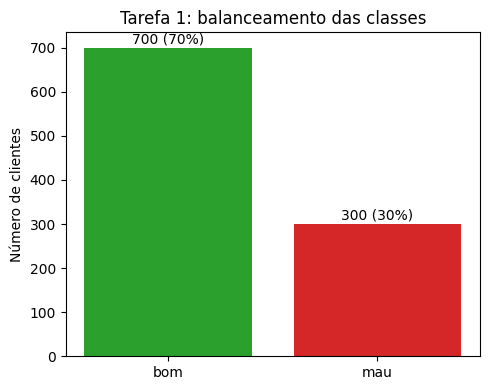

In [3]:
titulo("TAREFA 1 - Preparação dos dados")

print(f"Atributos numéricos   ({len(NUMERICAS)}): {NUMERICAS}")
print(f"Atributos categóricos ({len(CATEGORICAS)}): {CATEGORICAS}")
print("\nNúmero de categorias de cada atributo categórico:")
card = X[CATEGORICAS].nunique().sort_values(ascending=False)
print(card.to_string())
n_dummies = int(card.sum())
print(f"\nApós o one-hot: {n_dummies} colunas binárias + {len(NUMERICAS)} numéricas "
      f"= {n_dummies + len(NUMERICAS)} variáveis de entrada")

# Balanceamento das classes
cont = y.value_counts().sort_index()
print("\nDistribuição das classes:")
print(pd.DataFrame({"classe": CLASSES, "amostras": cont.values,
                    "proporção": (cont / len(y)).round(3).values}).to_string(index=False))

# O que significa "acertar 70%" quando 70% dos clientes são bons?
print("\nClassificador que aprova TODOS os clientes (sempre 'bom'):")
print(f"  acurácia = {(y == 0).mean():.1%} | recall do 'mau' = 0,0% | "
      f"custo (matriz 5:1) = {CUSTO_FN * (y == 1).sum()}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(CLASSES, cont.values, color=["tab:green", "tab:red"])
for i, v in enumerate(cont.values):
    ax.text(i, v + 10, f"{v} ({v / len(y):.0%})", ha="center")
ax.set_ylabel("Número de clientes")
ax.set_title("Tarefa 1: balanceamento das classes")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_distribuicao_classes.png", dpi=150)
plt.show()

# ----------------------------------------------------------------------------
# TAREFA 2 - Por que a árvore NÃO precisa de normalização (justificativa)
# ----------------------------------------------------------------------------
# Cada nó da árvore testa uma condição do tipo  x_j <= limiar  e escolhe o par
# (atributo, limiar) que melhor separa as classes. A normalização (z-score ou
# min-max) é uma transformação MONÓTONA CRESCENTE de x_j: ela não muda a
# ORDEM das amostras ao longo do atributo, só os valores numéricos. Então as
# mesmas partições são possíveis, com o mesmo ganho de pureza; só o valor
# numérico do limiar muda. Diferente do k-NN, nenhuma distância é calculada
# entre atributos, logo a escala deles nunca é comparada. A demonstração
# empírica está no final da Tarefa 3 (precisa da divisão treino/teste).

## TAREFA 3 - Divisão treino/teste estratificada (80% / 20%)

In [4]:
titulo("TAREFA 3 - Divisão treino/teste estratificada (80% / 20%)")

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
tab_div = pd.DataFrame({
    "treino": y_treino.value_counts().sort_index(),
    "teste": y_teste.value_counts().sort_index(),
})
tab_div.index = CLASSES
tab_div["% treino"] = (tab_div["treino"] / tab_div["treino"].sum() * 100).round(1)
tab_div["% teste"] = (tab_div["teste"] / tab_div["teste"].sum() * 100).round(1)
print(f"Treino: {len(X_treino)} | Teste: {len(X_teste)}")
print(tab_div)


TAREFA 3 - Divisão treino/teste estratificada (80% / 20%)
Treino: 800 | Teste: 200
     treino  teste  % treino  % teste
bom     560    140      70.0     70.0
mau     240     60      30.0     30.0


In [5]:
# --- Verificação empírica da Tarefa 2: com e sem padronização ------------------
titulo("TAREFA 2 (verificação empírica) - árvore com e sem padronização")
sem = montar_modelo(max_depth=5, escalar=False).fit(X_treino, y_treino)
com = montar_modelo(max_depth=5, escalar=True).fit(X_treino, y_treino)
p_sem, p_com = sem.predict(X_teste), com.predict(X_teste)
a_sem, a_com = sem.named_steps["arvore"], com.named_steps["arvore"]
print("Árvore (profundidade 5, gini) com e sem padronizar as variáveis numéricas:")
print(f"  acurácia no teste  SEM padronização: {accuracy_score(y_teste, p_sem):.4f}")
print(f"  acurácia no teste  COM padronização: {accuracy_score(y_teste, p_com):.4f}")
print(f"  previsões idênticas no teste: {(p_sem == p_com).mean():.1%}")
print(f"  mesmo número de nós: {a_sem.tree_.node_count == a_com.tree_.node_count} "
      f"({a_sem.tree_.node_count} nós) | mesmos atributos nos cortes: "
      f"{np.array_equal(a_sem.tree_.feature, a_com.tree_.feature)}")


TAREFA 2 (verificação empírica) - árvore com e sem padronização
Árvore (profundidade 5, gini) com e sem padronizar as variáveis numéricas:
  acurácia no teste  SEM padronização: 0.6450
  acurácia no teste  COM padronização: 0.6450
  previsões idênticas no teste: 100.0%
  mesmo número de nós: True (53 nós) | mesmos atributos nos cortes: True


## TAREFA 4 - Controle de complexidade (profundidade máxima) e critério de divisão


TAREFA 4 - Profundidade máxima: validação cruzada 5-fold no treino
Árvore SEM limite: profundidade real = 18, folhas = 149

Critério = gini
              acc_treino  acc_validação  desvio_val  recall_mau_val  precisão_mau_val
profundidade                                                                         
2                 0.7081         0.6888      0.0139          0.1333            0.1663
3                 0.7453         0.6975      0.0353          0.3667            0.4681
5                 0.8041         0.6975      0.0281          0.4417            0.4843
7                 0.8784         0.7112      0.0266          0.5292            0.5177
10                0.9575         0.6862      0.0266          0.5125            0.4800
sem limite        1.0000         0.6788      0.0292          0.4875            0.4713
-> melhor profundidade (gini): 7 (acurácia de validação = 0.7112)

Critério = entropy
              acc_treino  acc_validação  desvio_val  recall_mau_val  precisão_mau_val

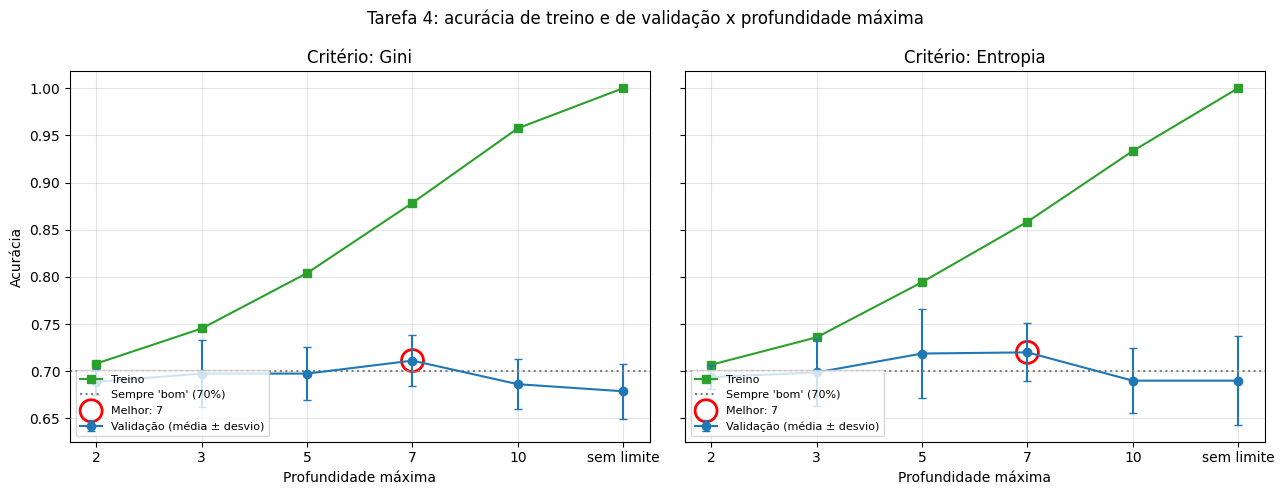


Modelo principal: critério gini, max_depth = 7


In [6]:
titulo("TAREFA 4 - Profundidade máxima: validação cruzada 5-fold no treino")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"acc": "accuracy", "rec_mau": "recall",
           "prec_mau": make_scorer(precision_score, zero_division=0)}

# Profundidade real da árvore sem limite (ajustada em todo o treino)
livre = montar_modelo(max_depth=None).fit(X_treino, y_treino).named_steps["arvore"]
print(f"Árvore SEM limite: profundidade real = {livre.get_depth()}, "
      f"folhas = {livre.get_n_leaves()}")

resultados = {}
melhor_prof = {}
for crit in ("gini", "entropy"):
    linhas = []
    for prof, nome in zip(PROFUNDIDADES, NOMES_PROF):
        r = cross_validate(montar_modelo(max_depth=prof, criterion=crit),
                           X_treino, y_treino, cv=cv, scoring=scoring,
                           return_train_score=True)
        linhas.append({
            "profundidade": nome,
            "acc_treino": r["train_acc"].mean(),
            "acc_validação": r["test_acc"].mean(),
            "desvio_val": r["test_acc"].std(),
            "recall_mau_val": r["test_rec_mau"].mean(),
            "precisão_mau_val": r["test_prec_mau"].mean(),
        })
    tab = pd.DataFrame(linhas).set_index("profundidade")
    resultados[crit] = tab
    melhor_prof[crit] = escolher_profundidade(tab["acc_validação"].to_numpy())
    print(f"\nCritério = {crit}")
    print(tab.round(4))
    print(f"-> melhor profundidade ({crit}): {melhor_prof[crit]} "
          f"(acurácia de validação = {tab['acc_validação'].max():.4f})")

# Comparação gini x entropia
cmp = pd.DataFrame({
    "val_gini": resultados["gini"]["acc_validação"],
    "val_entropia": resultados["entropy"]["acc_validação"],
})
cmp["diferença"] = cmp["val_entropia"] - cmp["val_gini"]
print("\nComparação gini x entropia (acurácia média de validação):")
print(cmp.round(4))
print(f"Maior |diferença| entre os critérios: {cmp['diferença'].abs().max():.4f} "
      f"(desvio padrão típico da validação ≈ "
      f"{resultados['gini']['desvio_val'].mean():.3f})")

# Figura: acurácia de treino e de validação x profundidade (um painel por critério)
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
x = np.arange(len(NOMES_PROF))
for ax, crit, nome in zip(eixos, ("gini", "entropy"), ("Gini", "Entropia")):
    tab = resultados[crit]
    ax.plot(x, tab["acc_treino"], marker="s", color="tab:green", label="Treino")
    ax.errorbar(x, tab["acc_validação"], yerr=tab["desvio_val"], marker="o",
                capsize=3, color="tab:blue", label="Validação (média ± desvio)")
    ax.axhline(0.70, color="gray", ls=":", label="Sempre 'bom' (70%)")
    i_melhor = PROFUNDIDADES.index(melhor_prof[crit])
    ax.scatter([i_melhor], [tab["acc_validação"].iloc[i_melhor]], s=250,
               facecolors="none", edgecolors="red", linewidths=2,
               label=f"Melhor: {NOMES_PROF[i_melhor]}")
    ax.set_xticks(x, NOMES_PROF)
    ax.set_xlabel("Profundidade máxima")
    ax.set_title(f"Critério: {nome}")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
eixos[0].set_ylabel("Acurácia")
fig.suptitle("Tarefa 4: acurácia de treino e de validação x profundidade máxima")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t4_profundidade.png", dpi=150)
plt.show()

# O modelo principal usa o critério gini (padrão) com a profundidade escolhida
PROF = melhor_prof["gini"]
print(f"\nModelo principal: critério gini, max_depth = {PROF}")

## TAREFA 5 - Interpretação: árvore, importâncias e regras

In [7]:
titulo(f"TAREFA 5 - Interpretação da árvore (gini, profundidade {PROF})")

modelo = montar_modelo(max_depth=PROF, criterion="gini").fit(X_treino, y_treino)
pre, arvore = modelo.named_steps["pre"], modelo.named_steps["arvore"]
nomes_brutos = pre.get_feature_names_out()          # ex.: 'cat__status_conta_A11'
print(f"Profundidade real: {arvore.get_depth()} | folhas: {arvore.get_n_leaves()} "
      f"| nós: {arvore.tree_.node_count}")


def decompor(nome_feat):
    """'cat__status_conta_A11' -> ('status_conta', 'A11'); 'num__idade' -> ('idade', None)."""
    if nome_feat.startswith("num__"):
        return nome_feat[len("num__"):], None
    resto = nome_feat[len("cat__"):]
    for col in CATEGORICAS:
        if resto.startswith(col + "_"):
            return col, resto[len(col) + 1:]
    raise ValueError(nome_feat)


# nomes curtos para o gráfico da árvore
nomes_curtos = []
for n in nomes_brutos:
    col, cod = decompor(n)
    nomes_curtos.append(col if cod is None else f"{col} = {cod}")


TAREFA 5 - Interpretação da árvore (gini, profundidade 7)
Profundidade real: 7 | folhas: 59 | nós: 117


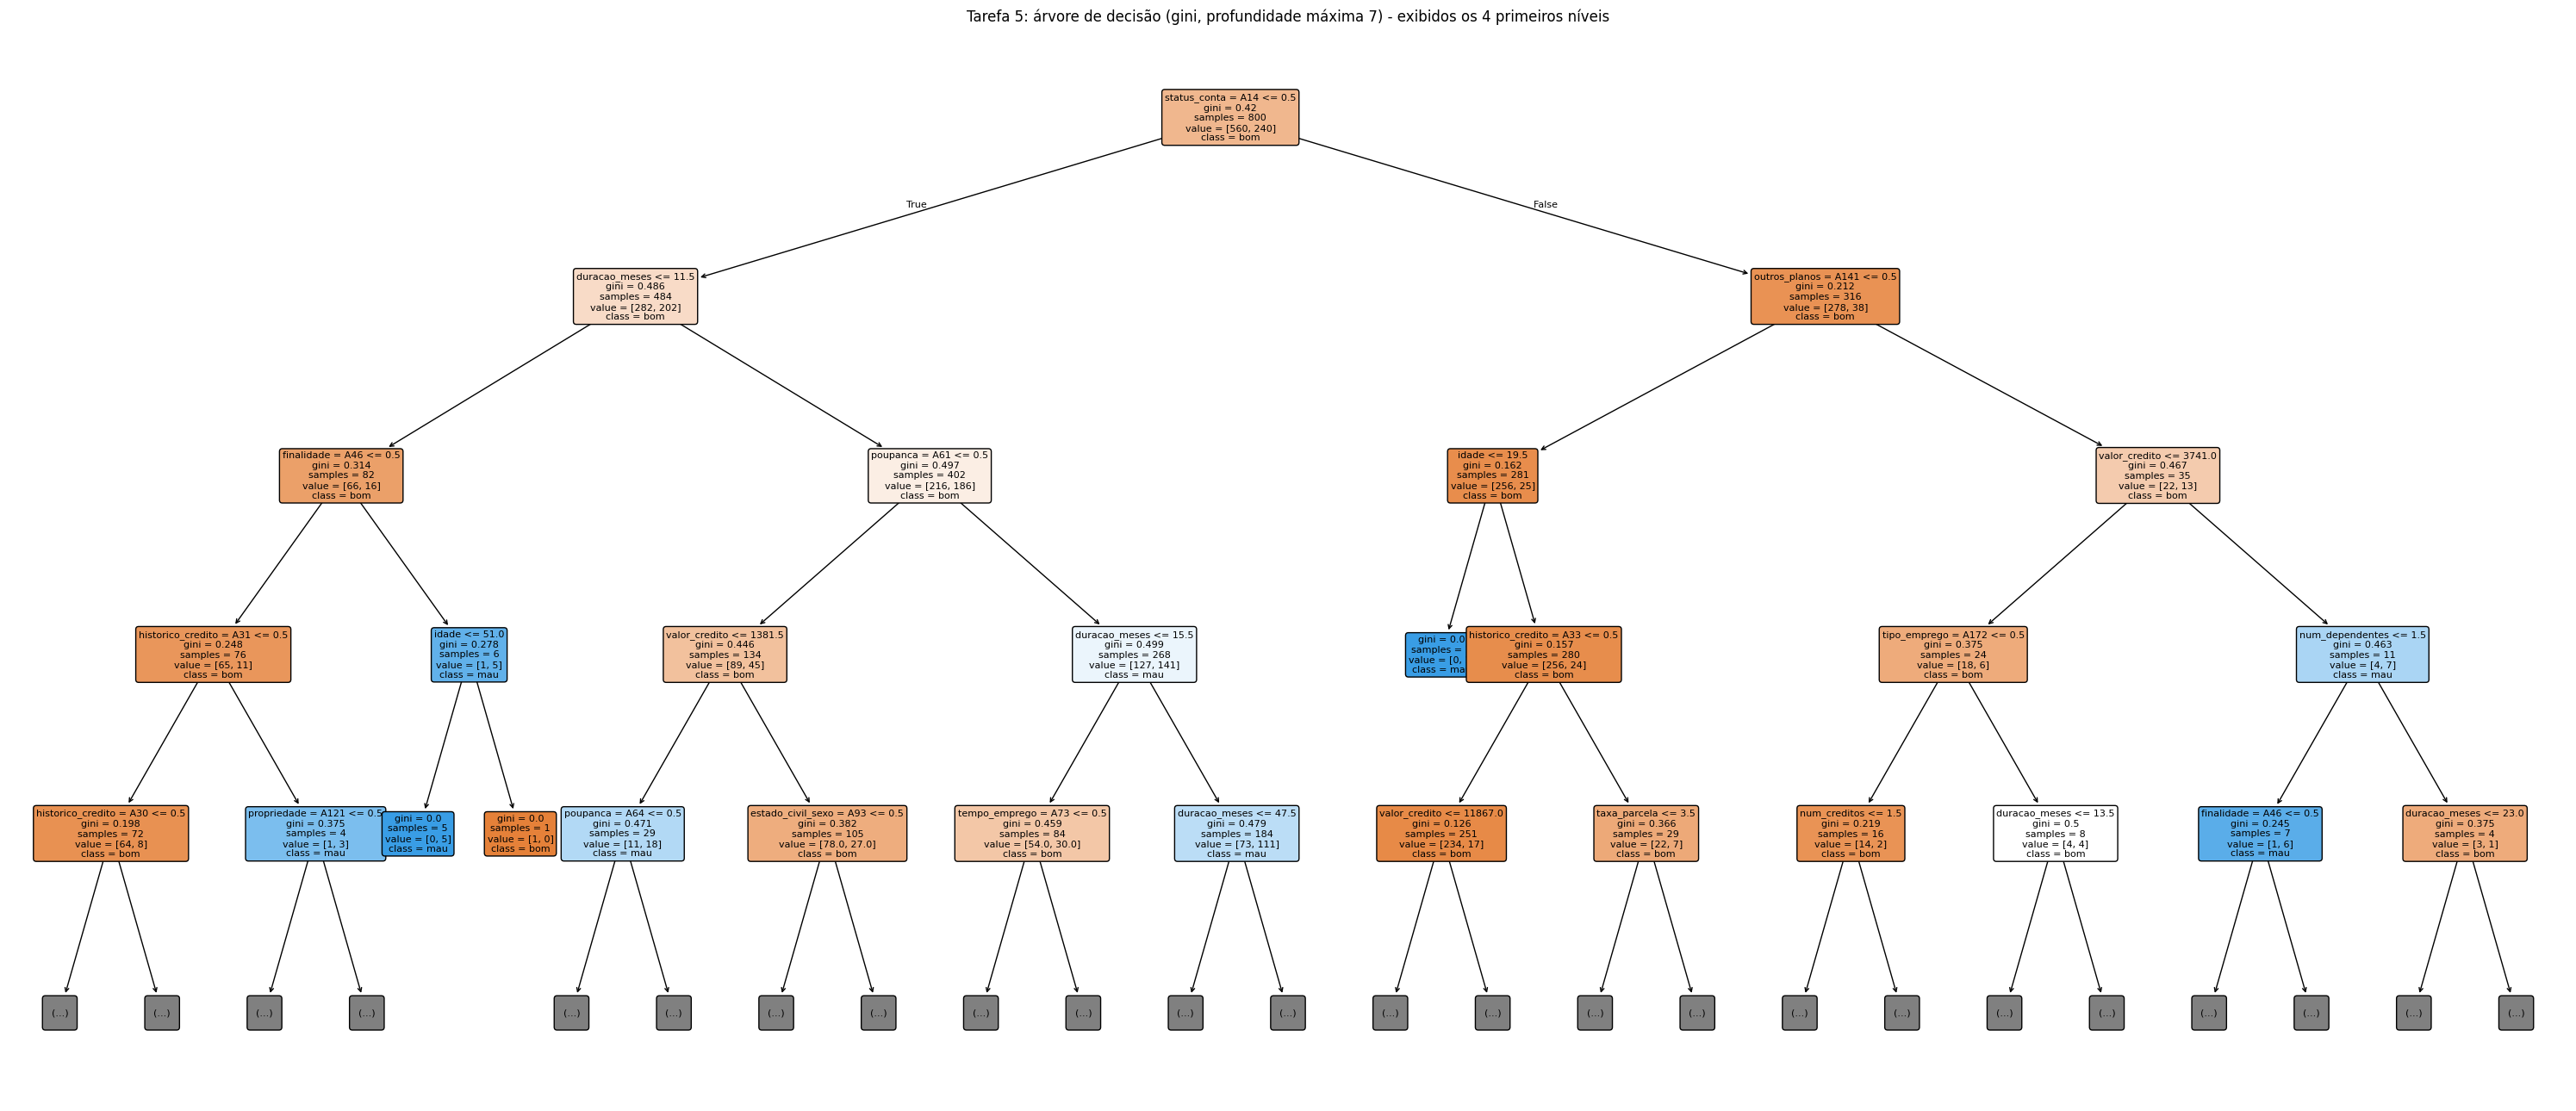

9265

In [8]:
# --- (a) Visualização gráfica da árvore ---------------------------------------
prof_plot = min(arvore.get_depth(), 4)  # árvores muito fundas não cabem na figura
fig, ax = plt.subplots(figsize=(30, 13))
plot_tree(arvore, feature_names=nomes_curtos, class_names=CLASSES, filled=True,
          rounded=True, impurity=True, proportion=False, fontsize=8,
          max_depth=prof_plot, ax=ax)
ax.set_title(f"Tarefa 5: árvore de decisão (gini, profundidade máxima {PROF})"
             + (f" - exibidos os {prof_plot} primeiros níveis" if prof_plot < arvore.get_depth() else ""))
fig.tight_layout()
fig.savefig(PASTA_FIG / "t5_arvore.png", dpi=110)
plt.show()

# Texto da árvore completa (útil para auditoria)
texto_arvore = export_text(arvore, feature_names=nomes_curtos, show_weights=True)
(BASE / "arvore_texto.txt").write_text(texto_arvore, encoding="utf-8")


Importância por coluna da árvore (top 10; soma = 1):
status_conta = A14      0.1858
duracao_meses           0.1408
valor_credito           0.1143
finalidade = A46        0.0478
tempo_emprego = A73     0.0357
poupanca = A61          0.0356
taxa_parcela            0.0333
outros_planos = A141    0.0273
poupanca = A64          0.0256
tempo_emprego = A72     0.0251

Importância AGREGADA por atributo original (soma das dummies):
status_conta         0.1881
duracao_meses        0.1408
valor_credito        0.1143
poupanca             0.0804
propriedade          0.0724
finalidade           0.0705
tempo_emprego        0.0655
historico_credito    0.0640
outros_planos        0.0373
taxa_parcela         0.0333
moradia              0.0255
estado_civil_sexo    0.0235
idade                0.0183
tempo_residencia     0.0172
num_creditos         0.0138
telefone             0.0116
num_dependentes      0.0103
tipo_emprego         0.0083
outros_devedores     0.0048

Os três atributos mais determinantes: [

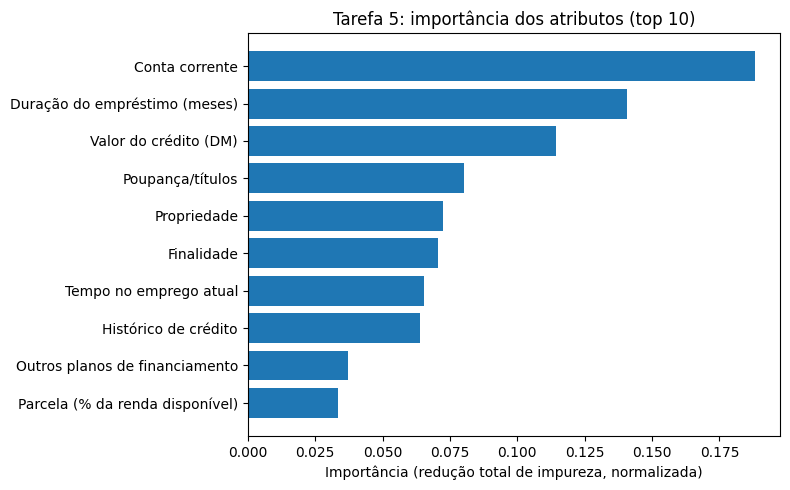

In [9]:
# --- (b) Importância dos atributos --------------------------------------------
imp = pd.Series(arvore.feature_importances_, index=nomes_curtos)
print("\nImportância por coluna da árvore (top 10; soma = 1):")
print(imp.sort_values(ascending=False).head(10).round(4).to_string())

# Agrega as dummies do mesmo atributo original (ex.: status_conta = A11..A14)
imp_atrib = {}
for n, v in zip(nomes_brutos, arvore.feature_importances_):
    col, _ = decompor(n)
    imp_atrib[col] = imp_atrib.get(col, 0.0) + v
imp_atrib = pd.Series(imp_atrib).sort_values(ascending=False)
print("\nImportância AGREGADA por atributo original (soma das dummies):")
print(imp_atrib[imp_atrib > 0].round(4).to_string())
top3 = list(imp_atrib.index[:3])
print(f"\nOs três atributos mais determinantes: "
      f"{[ROTULO_ATRIB[a] for a in top3]}")
print(f"Juntos respondem por {imp_atrib.iloc[:3].sum():.1%} da importância total.")

fig, ax = plt.subplots(figsize=(8, 5))
top = imp_atrib.head(10)[::-1]
ax.barh([ROTULO_ATRIB[a] for a in top.index], top.values, color="tab:blue")
ax.set_xlabel("Importância (redução total de impureza, normalizada)")
ax.set_title("Tarefa 5: importância dos atributos (top 10)")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t5_importancia_atributos.png", dpi=150)
plt.show()

In [11]:
# --- (c) Regra da folha com mais amostras de MAU risco -------------------------
Xt_treino = pre.transform(X_treino)
folha_de_cada = arvore.apply(Xt_treino)                 # folha de cada amostra de treino
t = arvore.tree_
folhas = np.where(t.children_left == -1)[0]
y_tr = y_treino.to_numpy()
tab_folhas = pd.DataFrame({
    "folha": folhas,
    "amostras": [int((folha_de_cada == f).sum()) for f in folhas],
    "mau": [int(((folha_de_cada == f) & (y_tr == 1)).sum()) for f in folhas],
})
tab_folhas["bom"] = tab_folhas["amostras"] - tab_folhas["mau"]
tab_folhas["pct_mau"] = tab_folhas["mau"] / tab_folhas["amostras"]
tab_folhas["previsão"] = np.where(tab_folhas["mau"] > tab_folhas["bom"], "mau", "bom")
print("\nFolhas com mais amostras de mau risco (treino):")
print(tab_folhas.sort_values("mau", ascending=False).head(5).round(3).to_string(index=False))


def regras_da_folha(folha):
    """Escreve em linguagem natural o caminho raiz -> folha.

    Condições repetidas sobre o mesmo atributo numérico são fundidas em um
    intervalo (ex.: 'duração > 11,5' e 'duração > 15,5' viram 'duração > 15,5').
    """
    idx = int(np.where(folha_de_cada == folha)[0][0])  # uma amostra que cai na folha
    caminho = arvore.decision_path(Xt_treino[idx:idx + 1]).indices
    intervalos = {}   # atributo numérico -> [limite inferior, limite superior]
    categ = {}        # atributo categórico -> ('=', código) ou lista de '≠'
    ordem = []        # ordem de aparição dos atributos
    for no in caminho[:-1]:  # o último nó do caminho é a folha
        feat, limiar = t.feature[no], t.threshold[no]
        col, cod = decompor(nomes_brutos[feat])
        esquerda = Xt_treino[idx, feat] <= limiar
        if col not in ordem:
            ordem.append(col)
        if cod is None:  # numérico: <= limiar (esquerda) ou > limiar (direita)
            lo, hi = intervalos.setdefault(col, [-np.inf, np.inf])
            if esquerda:
                intervalos[col][1] = min(hi, limiar)
            else:
                intervalos[col][0] = max(lo, limiar)
        else:  # dummy: <= 0,5 significa "NÃO é esta categoria"
            igual, diferentes = categ.setdefault(col, [None, []])
            if esquerda:
                diferentes.append(cod)
            else:
                categ[col][0] = cod
    frases = []
    for col in ordem:
        if col in intervalos:
            lo, hi = intervalos[col]
            rot = ROTULO_ATRIB[col]
            if np.isfinite(lo) and np.isfinite(hi):
                frases.append(f"{lo:.1f} < {rot} <= {hi:.1f}")
            elif np.isfinite(lo):
                frases.append(f"{rot} > {lo:.1f}")
            else:
                frases.append(f"{rot} <= {hi:.1f}")
        else:
            igual, diferentes = categ[col]
            if igual is not None:  # "é X" já implica "não é nenhuma outra"
                frases.append(f"{ROTULO_ATRIB[col]} = {igual} ({DESCRICAO[col][igual]})")
            else:
                nao = " e ".join(f"{c} ({DESCRICAO[col][c]})" for c in diferentes)
                frases.append(f"{ROTULO_ATRIB[col]} não é {nao}")
    return frases


def imprimir_regra(folha):
    linha = tab_folhas[tab_folhas["folha"] == folha].iloc[0]
    print("  SE  " + "\n  E   ".join(regras_da_folha(folha)))
    print(f"  ENTÃO prever: {linha['previsão'].upper()} pagador "
          f"(nesta folha: {int(linha['amostras'])} clientes do treino, "
          f"{int(linha['mau'])} maus = {linha['pct_mau']:.1%}, {int(linha['bom'])} bons)")


# (c1) Folha com MAIOR NÚMERO de amostras de mau risco (a pedida no enunciado)
folha_alvo = int(tab_folhas.sort_values(["mau", "amostras"], ascending=False).iloc[0]["folha"])
print(f"\n(c1) Caminho da raiz até a folha {folha_alvo} "
      f"(a que reúne mais maus pagadores do treino):")
imprimir_regra(folha_alvo)

# (c2) Complementar: entre as folhas que PREVEEM 'mau', a que reúne mais maus
cand = tab_folhas[tab_folhas["previsão"] == "mau"].sort_values(["mau", "amostras"], ascending=False)
folha_mau = int(cand.iloc[0]["folha"])
print(f"\n(c2) Complementar - folha {folha_mau}: a que mais reúne maus pagadores "
      f"entre as que PREVEEM 'mau':")
imprimir_regra(folha_mau)


Folhas com mais amostras de mau risco (treino):
 folha  amostras  mau  bom  pct_mau previsão
    67        97   44   53    0.454      bom
    65        38   24   14    0.632      mau
    49        30   20   10    0.667      mau
    71        17   17    0    1.000      mau
    27        16   16    0    1.000      mau

(c1) Caminho da raiz até a folha 67 (a que reúne mais maus pagadores do treino):
  SE  Conta corrente não é A14 (sem conta corrente)
  E   15.5 < Duração do empréstimo (meses) <= 47.5
  E   Poupança/títulos = A61 (< 100 DM)
  E   2321.0 < Valor do crédito (DM) <= 8015.5
  ENTÃO prever: BOM pagador (nesta folha: 97 clientes do treino, 44 maus = 45.4%, 53 bons)

(c2) Complementar - folha 65: a que mais reúne maus pagadores entre as que PREVEEM 'mau':
  SE  Conta corrente não é A14 (sem conta corrente)
  E   15.5 < Duração do empréstimo (meses) <= 47.5
  E   Poupança/títulos = A61 (< 100 DM)
  E   Valor do crédito (DM) <= 2321.0
  E   Outros planos de financiamento = A143 (n

## TAREFA 6 - Avaliação no teste

In [12]:
titulo("TAREFA 6 - Avaliação no conjunto de teste")

y_prev = modelo.predict(X_teste)
print(f"Acurácia no teste: {accuracy_score(y_teste, y_prev):.4f}")
cm = confusion_matrix(y_teste, y_prev, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("\nMatriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(cm, index=["real bom", "real mau"], columns=["prev bom", "prev mau"]))
print("\nMétricas por classe:")
print(classification_report(y_teste, y_prev, labels=[0, 1], target_names=CLASSES,
                            digits=4, zero_division=0))
print("Tipos de erro:")
print(f"  FN (mau pagador APROVADO como bom) = {fn}  -> custo {CUSTO_FN} cada = {CUSTO_FN * fn}")
print(f"  FP (bom pagador RECUSADO como mau) = {fp}  -> custo {CUSTO_FP} cada = {CUSTO_FP * fp}")
custo_modelo = custo_total(y_teste, y_prev)
custo_aprova_todos = CUSTO_FN * int((y_teste == 1).sum())
print(f"  Custo total do modelo (matriz 5:1 do german.doc): {custo_modelo}")
print(f"  Custo de aprovar todos os clientes:              {custo_aprova_todos}")


TAREFA 6 - Avaliação no conjunto de teste
Acurácia no teste: 0.6800

Matriz de confusão (linhas = real, colunas = previsto):
          prev bom  prev mau
real bom       110        30
real mau        34        26

Métricas por classe:
              precision    recall  f1-score   support

         bom     0.7639    0.7857    0.7746       140
         mau     0.4643    0.4333    0.4483        60

    accuracy                         0.6800       200
   macro avg     0.6141    0.6095    0.6115       200
weighted avg     0.6740    0.6800    0.6767       200

Tipos de erro:
  FN (mau pagador APROVADO como bom) = 34  -> custo 5 cada = 170
  FP (bom pagador RECUSADO como mau) = 30  -> custo 1 cada = 30
  Custo total do modelo (matriz 5:1 do german.doc): 200
  Custo de aprovar todos os clientes:              300



TAREFA 6 (ajuste) - class_weight para reduzir maus pagadores aprovados
Validação cruzada 5-fold no TREINO (previsões fora da amostra):
                 acurácia  recall_mau  precisão_mau  custo_por_cliente
class_weight                                                          
nenhum (padrão)    0.7113      0.5292        0.5184             0.8538
balanced           0.6612      0.6625        0.4556             0.7438
custo 5:1          0.6412      0.7625        0.4431             0.6438

Menor custo na validação cruzada: custo 5:1

Resultado no TESTE:
                          acurácia  recall_mau  precisão_mau  FN  FP  custo_total
modelo padrão                0.680      0.4333        0.4643  34  30          200
class_weight = custo 5:1     0.585      0.7667        0.4000  14  69          139


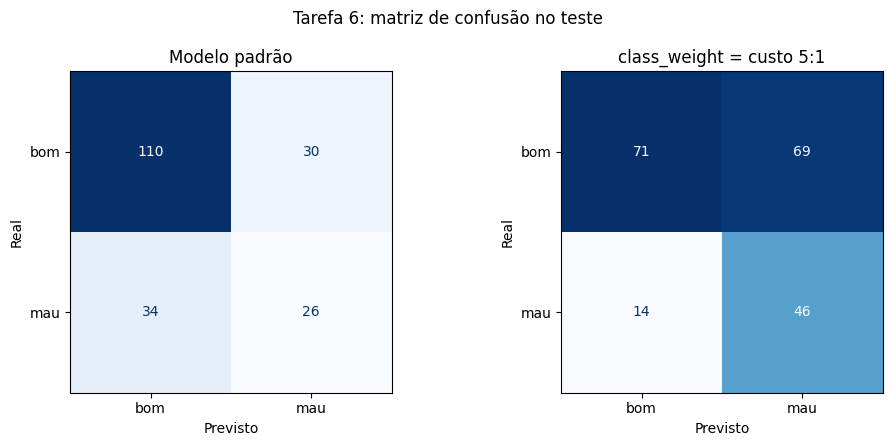


Referência (aprovar todos): acurácia no teste = 0.7000, recall do 'mau' = 0


In [14]:
# --- Ajuste de treinamento para reduzir o erro mais grave (FN) -----------------
# Usa 'class_weight' (penaliza mais os erros na classe 'mau'). A escolha entre as
# opções é feita por validação cruzada NO TREINO (sem olhar o teste), pelo custo
# da matriz 5:1.
titulo("TAREFA 6 (ajuste) - class_weight para reduzir maus pagadores aprovados")

opcoes = {
    "nenhum (padrão)": None,
    "balanced": "balanced",
    "custo 5:1": {0: 1, 1: 5},
}
linhas = []
for nome, cw in opcoes.items():
    prev_cv = cross_val_predict(
        montar_modelo(max_depth=PROF, criterion="gini", class_weight=cw),
        X_treino, y_treino, cv=cv)
    linhas.append({
        "class_weight": nome,
        "acurácia": accuracy_score(y_treino, prev_cv),
        "recall_mau": recall_score(y_treino, prev_cv),
        "precisão_mau": precision_score(y_treino, prev_cv, zero_division=0),
        "custo_por_cliente": custo_total(y_treino, prev_cv) / len(y_treino),
    })
tab_cw = pd.DataFrame(linhas).set_index("class_weight")
print("Validação cruzada 5-fold no TREINO (previsões fora da amostra):")
print(tab_cw.round(4))
melhor_cw = tab_cw["custo_por_cliente"].idxmin()
print(f"\nMenor custo na validação cruzada: {melhor_cw}")

modelo_aj = montar_modelo(max_depth=PROF, criterion="gini",
                          class_weight=opcoes[melhor_cw]).fit(X_treino, y_treino)
y_prev_aj = modelo_aj.predict(X_teste)
cm_aj = confusion_matrix(y_teste, y_prev_aj, labels=[0, 1])
tn2, fp2, fn2, tp2 = cm_aj.ravel()

comparacao = pd.DataFrame({
    "acurácia": [accuracy_score(y_teste, y_prev), accuracy_score(y_teste, y_prev_aj)],
    "recall_mau": [recall_score(y_teste, y_prev), recall_score(y_teste, y_prev_aj)],
    "precisão_mau": [precision_score(y_teste, y_prev, zero_division=0),
                     precision_score(y_teste, y_prev_aj, zero_division=0)],
    "FN": [fn, fn2], "FP": [fp, fp2],
    "custo_total": [custo_modelo, custo_total(y_teste, y_prev_aj)],
}, index=["modelo padrão", f"class_weight = {melhor_cw}"])
print("\nResultado no TESTE:")
print(comparacao.round(4))

# Figura: matrizes de confusão (padrão x ajustado)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, c, nome in zip(eixos, (cm, cm_aj), ("Modelo padrão", f"class_weight = {melhor_cw}")):
    ConfusionMatrixDisplay(c, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
fig.suptitle("Tarefa 6: matriz de confusão no teste")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t6_matriz_confusao.png", dpi=150)
plt.show()

# Referência: classificador que sempre aprova
base = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
print(f"\nReferência (aprovar todos): acurácia no teste = "
      f"{accuracy_score(y_teste, base.predict(X_teste)):.4f}, recall do 'mau' = 0")